# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** _UniTi_ · **Tema:** _Chat Bot de assitência tecnica_

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

In [1]:
import base64, csv, io, json, zlib
from hashlib import sha256
from pathlib import Path, PurePosixPath
from zipfile import ZIP_DEFLATED, ZipFile
from google.colab import files

enviados = files.upload()
zip_bytes = next(v for n, v in enviados.items() if n.lower().endswith(".zip"))
forms_bytes = next(v for n, v in enviados.items() if n.lower().endswith(".csv"))

# Índices e rótulos das frases selecionadas, em formato compacto.
selecoes = (
    "eNotlVGSJSEIBC/EhwJqe5aJvf81NtOZF9G+tkXAKgp/fkbMyOhYceKLG5MPM2bGrJgdc8XcMU/M"
    "L+aNHJHYZ2RFduSK3JEn8ou8USNqRuW/+JnDPWuzlK5v3hZe78Lz2AzzMKzBsI12cDpv43lgkhMT"
    "NhroY+jrto98sGEbsecuhtMMd5PKOAwTk0xMsofpcYLcJnrK1Y7mf7Hn6mvoK4cO9bX1dZYO9WW4"
    "NFyWvlpfBk4Dp4Ezi9NXM/RiWBuo9gXE+7ACkpzFQP7YLYbeDOtcIQLSqhPdM74P7C+4kxOwl9ix"
    "Z+4FC9+Bk/uB4rjiOcC+zKaF3dRzNybgXP1FL5j0ZGPgZspDN8Pe+P8+hnvZN4e+dFMeypi5PMpe"
    "UM2s+O9NXoP5JNRsVzbYzO/C/BiejwrJMof2kAv4ZEzCbklay7Ws9yfNQ3KlOddjPepR60TO52N6"
    "WxbHstBH6iP1kWlZlGXxvBlovLoJ6ZEda2FaC9NamFbAlPx5l5xaKVN2U3ZLdpfsboE4AsGs+RdW"
    "y2ACScFrnx1XKQwqfk6IZ4VhHTn/GO4AvIFJTk1gu86N/m7cVFcUwpyS2nye67MGEEUXeZfaA9PL"
    "+yI2Qjp8AB2iHr7AAXa1FBjEkif88HniYFDNoP0xxxiXQLLArT7+zFgrfFF6HHot7HaJeSHHIBEe"
    "dh09LwePT6KLCXgtUFDIVG0QZ+njuF+5jHxvRlFZnrOXfph8oVs9kBoIrW0kTT2zOhOtBZtL7zv2"
    "fAogKkW71JGnBbc9hqRaKCjgV7dD4Af1yXSwwyI1/InXGAbk7AcWwfcj4DnU/ujD+gHC/Tj93OVJ"
    "rrs4QD47MpHKcZ35KESAbIHJP1Uo2S0g/HjhsZgtw5naEaMf9UPdqOlXuNSQH+ys61ULzTD25rHq"
    "IGk/Fy9UWWcs+NGddIAtfj7vxJgTzdbNAbeO+nW1eA0EkPZ5Mix1Z+89ccj2jGWL+2vGJkOvCzsY"
    "3SpsySk88xuYukX1KcNm/ql7jFhDPIc+cIbf3WA3zD/h58vrQWDhe0zepoq2TcfxHVTp1uiQKGCQ"
    "WJ79150T1PLzqlnxrgQ9vDxA6rDrUM72bRowCybEy8HggNqxRy+vqHIX1q/Tsag7EDm2VzohC58W"
    "MgnhR6TTUhKTtGa4mhBkx1c2OY1BqvRbouo1UeZWU+1bX6lM33rR6FA5Z/2ozI+sP5ry97qE3qxN"
    "r1CPUPMN7vVpJ+wl37JeajyPLz4aA7JCWQUIXyk07cdv/66tvRcDqv2so/Y+KBRz2zb//Xaoxner"
    "j+aIDd39TnXfQEO8JnRdoh8piYa8S679eUnQfdr3p9aJBYsvsmrvoTvxgdQLAReC28vOnt3YXRJs"
    "YGqFU+/mID+QbM5+bUltVdU3/v37D7FhtRw="
)
teste_original, forms_treino, forms_teste, selecionadas = json.loads(
    zlib.decompress(base64.b64decode(selecoes))
)
rotulos = ["autenticacao", "ava", "chitchat", "email", "fora_dominio",
           "google_drive", "senha", "sistemas", "suporte", "wifi"]

def leitor(blob):
    return io.StringIO(blob.decode("utf-8-sig"), newline="")

with ZipFile(io.BytesIO(zip_bytes)) as origem:
    prefixo = "UniTi-ChatBot-main/"
    antigos = [origem.read(prefixo + "dados/" + nome)
               for nome in ("treino.csv", "teste.csv", "gerados_llm.csv")]
    hashes = [sha256(v).hexdigest()[:16] for v in antigos + [forms_bytes]]
    if hashes != ["426e3ab83ce28b24", "28d90ece79bcc8a3",
                  "459fd1e270f715a8", "03386bcc5de01bd2"]:
        raise ValueError("Envie o ZIP original e o mesmo CSV do Forms enviado no chat.")
    treino, teste, llm = [list(csv.DictReader(leitor(v))) for v in antigos]

    pasta = Path("/content/UniTi-ChatBot")
    if not (pasta / "grupo.yaml").exists():
        for info in origem.infolist():
            if not info.is_dir():
                nome = PurePosixPath(info.filename.removeprefix(prefixo))
                if nome.is_absolute() or ".." in nome.parts or not info.filename.startswith(prefixo):
                    raise ValueError("Caminho inesperado no ZIP.")
                destino = pasta.joinpath(*nome.parts)
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(origem.read(info))

formulario = csv.reader(leitor(forms_bytes))
next(formulario)
textos = [texto.strip() for linha in formulario for texto in linha[1:]]

def linha_forms(indice):
    texto, rotulo = divmod(indice, len(rotulos))
    return dict(texto=textos[texto], intencao=rotulos[rotulo], origem="coletado")

treino = treino + [linha_forms(i) for i in forms_treino] + [llm[i] for i in selecionadas]
teste = [teste[i] for i in teste_original] + [linha_forms(i) for i in forms_teste]
assert (len(treino), len(teste)) == (505, 141)

saida = Path("/content/CSV_UniTi_atualizados.zip")
with ZipFile(saida, "w", ZIP_DEFLATED) as arquivo:
    for nome, dados in [("treino.csv", treino), ("teste.csv", teste)]:
        destino = pasta / "dados" / nome
        with destino.open("w", encoding="utf-8", newline="") as f:
            escritor = csv.DictWriter(f, fieldnames=["texto", "intencao", "origem"])
            escritor.writeheader()
            escritor.writerows(dados)
        arquivo.write(destino, "dados/" + nome)

print("Pronto. O treino tem 505 frases e o teste tem 141.")
files.download(str(saida))

Saving UniTi-ChatBot-main (1).zip to UniTi-ChatBot-main (1).zip
Saving Ajude a testar um chatbot de suporte de TI da UFMS.csv to Ajude a testar um chatbot de suporte de TI da UFMS.csv
Pronto. O treino tem 505 frases e o teste tem 141.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 0. Ambiente

In [2]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/Guimaraes-Mendonca/UniTi-ChatBot.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [3]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [4]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: UniTi | Tema: UniTi - Chat Bot de Assistência com Tecnologias Acadêmicasr


,intenção,descrição
0,wifi,Ajuda com acesso e configuração da rede Wi-Fi institucional Eduroam.
1,email,Ajuda com acesso e configuração do e-mail institucional.
2,senha,Ajuda com recuperação e alteração de senha do Passaporte UFMS.
3,ava,Ajuda com acesso ao Ambiente Virtual de Aprendizagem.
4,sistemas,Ajuda com acesso e utilização dos sistemas acadêmicos e institucionais.
5,suporte,"Orientações sobre problemas técnicos, VPN e canais de suporte de TI."
6,google_drive,Ajuda com transferência de arquivos e utilização de drives compartilhados do...
7,autenticacao,Ajuda com configuração e utilização da autenticação de dois fatores do Gmail.


---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

### 2. Construção e Organização dos Dados

#### 🔨 Descrição da Construção dos Dados
- **Autoria e Coleta de Dados Reais (`coletado`)**: As mensagens humanas foram escritas por estudantes da UFMS através de formulário online (Google Forms). O integrante **Caio Magno** foi o responsável por estruturar a coleta, reunir as respostas e realizar a rotulagem manual da base `respostas_classificadas.csv`.
- **Conjunto de Teste (`teste.csv`)**: Composto 100% por frases de origem humana/coletada (33 frases), garantindo **vazamento zero** em relação ao treino (`vazamento = 0`) e cobrindo todas as intenções.
- **Geração de Dados Sintéticos (`llm`)**: Foram geradas 78 frases de treino via LLM (ChatGPT) a partir de prompts em múltiplos estilos de escrita (formal, informal, com erros ortográficos, ansioso e curto) para expandir o treino. As frases sintéticas foram revisadas pelo grupo, mantendo **40% de origem humana no treino** (acima do mínimo de 20% exigido).
- **Negativos Difíceis (`fora_dominio`)**: A classe foi abastecida com perguntas sobre serviços universitários vizinhos (renovação de livros na biblioteca, cardápio do RU, transporte acadêmico e auxílios), que utilizam vocabulário similar ao de TI para testar a fronteira do classificador de escopo.

---

#### 📝 RELATÓRIO: Tabela Intenção × Origem (Treino e Teste)

##### Tabela do Conjunto de Treino (`treino.csv`)
| Intenção | Coletado | LLM | Total Treino |
| :--- | :---: | :---: | :---: |
| `fora_dominio` | 18 | 20 | **38** |
| `chitchat` | 14 | 10 | **24** |
| `wifi` | 6 | 6 | **12** |
| `sistemas` | 5 | 6 | **11** |
| `email` | 3 | 6 | **9** |
| `senha` | 3 | 6 | **9** |
| `suporte` | 3 | 6 | **9** |
| `autenticacao` | 0 | 6 | **6** |
| `ava` | 0 | 6 | **6** |
| `google_drive` | 0 | 6 | **6** |
| **Total Geral** | **52 (40%)** | **78 (60%)** | **130** |

##### Tabela do Conjunto de Teste (`teste.csv`)
| Intenção | Coletado | LLM | Total Teste |
| :--- | :---: | :---: | :---: |
| `fora_dominio` | 12 | 0 | **12** |
| `chitchat` | 8 | 0 | **8** |
| `wifi` | 3 | 0 | **3** |
| `sistemas` | 3 | 0 | **3** |
| `senha` | 2 | 0 | **2** |
| `email` | 1 | 0 | **1** |
| `suporte` | 1 | 0 | **1** |
| `autenticacao` | 1 | 0 | **1** |
| `ava` | 1 | 0 | **1** |
| `google_drive` | 1 | 0 | **1** |
| **Total Geral** | **33 (100%)** | **0 (0%)** | **33** |

In [7]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,coletado,llm,total
intencao,,,
autenticacao,0,50,50
ava,0,50,50
chitchat,27,10,37
email,3,47,50
fora_dominio,48,20,68
google_drive,0,50,50
senha,7,43,50
sistemas,9,41,50
suporte,3,47,50


origem,coletado,total
intencao,,
autenticacao,3,3
ava,5,5
chitchat,30,30
email,3,3
fora_dominio,40,40
google_drive,3,3
senha,15,15
sistemas,15,15
suporte,12,12


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [9]:
gerados = pd.read_csv("dados/gerados_llm.csv")
gerados.sample(15, random_state=42)

,texto,intencao,origem
628,"Quero alterar minha senha do Passaporte UFMS por segurança, mas não sei por ...",senha,llm
680,Aulas virtuais indisponíveis,ava,llm
1085,tem como recuperar meu acesso ao passaporte ufms sem saber a senha,senha,llm
578,Não estou conseguindo entrar no meu e-mail institucional e preciso consultar...,email,llm
1010,Wi-Fi da universidade,wifi,llm
759,como faço pra registrar um chamado de suporte de TI pelo celular,suporte,llm
931,Perdi o celular usado para confirmar meu acesso ao Gmail. Quais alternativas...,autenticacao,llm
727,Grade de horários,sistemas,llm
70,nao consigo entrar no email institucional aparece que minha conta nao existe,email,llm
123,minha senha do passaporte ufms venceu como troco ela,senha,llm


🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

In [10]:
# 🔨 TODO: Análise exploratória
import pandas as pd
import numpy as np
from collections import Counter
import os

# 1. Carregar dados de treino
path_treino = "dados/treino.csv" if os.path.exists("dados/treino.csv") else "treino.csv"
df_treino = pd.read_csv(path_treino)

# 2. Métricas de tamanho das mensagens
df_treino["qtd_palavras"] = df_treino["texto"].astype(str).apply(lambda x: len(x.split()))
df_treino["qtd_caracteres"] = df_treino["texto"].astype(str).str.len()

print("=== 1. TAMANHO DAS MENSAGENS POR CLASSE (MÉDIA E MEDIANA) ===")
tamanho_por_classe = df_treino.groupby("intencao")["qtd_palavras"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)
print(tamanho_por_classe)

print("\n=== 2. DIFERENÇAS ENTRE FRASES HUMANAS (COLETADO) E LLM ===")
tamanho_por_origem = df_treino.groupby("origem")["qtd_palavras"].agg(["count", "mean", "median", "std"]).round(2)
print(tamanho_por_origem)

print("\n=== 3. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (EXCLUINDO STOPWORDS) ===")
stopwords_pt = set(["a", "ao", "aos", "as", "até", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "esta", "está", "eu", "foi", "isso", "já", "mais", "mas", "me", "meu", "minha", "na", "nas", "no", "nos", "o", "os", "ou", "para", "pela", "pelo", "por", "qual", "quando", "que", "quem", "se", "sem", "ser", "sua", "tem", "um", "uma", "você", "pra", "oq", "pq", "ter", "tenho"])

for intencao, grp in df_treino.groupby("intencao"):
    palavras = []
    for txt in grp["texto"]:
        tokens = [w.lower().strip("?,!.:;") for w in txt.split() if w.lower().strip("?,!.:;") not in stopwords_pt and len(w) > 2]
        palavras.extend(tokens)
    top_words = Counter(palavras).most_common(5)
    print(f"• {intencao:15s}: {', '.join([f'{w}({c})' for w, c in top_words])}")

print("\n=== 4. EXEMPLOS DE NEGATIVOS DIFÍCEIS (fora_dominio) ===")
negativos_dificeis = df_treino[df_treino["intencao"] == "fora_dominio"]["texto"].head(5).tolist()
for i, ex in enumerate(negativos_dificeis, 1):
    print(f"{i}. \"{ex}\"")

=== 1. TAMANHO DAS MENSAGENS POR CLASSE (MÉDIA E MEDIANA) ===
              count   mean  median   std  min  max
intencao                                          
autenticacao     50  15.04    13.0  7.16    4   31
ava              50  15.00    14.0  5.30    5   25
chitchat         37   4.70     4.0  2.43    1   12
email            50  13.92    13.0  4.95    4   23
fora_dominio     68   8.03     8.0  2.90    1   18
google_drive     50  16.96    15.5  6.23    4   28
senha            50  12.46    12.0  4.66    4   22
sistemas         50  12.42    10.0  5.71    4   25
suporte          50  16.10    14.0  5.98    4   31
wifi             50  13.78    12.5  5.83    3   26

=== 2. DIFERENÇAS ENTRE FRASES HUMANAS (COLETADO) E LLM ===
          count   mean  median   std
origem                              
coletado    111   7.83     7.0  4.37
llm         394  14.30    13.0  5.99

=== 3. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (EXCLUINDO STOPWORDS) ===
• autenticacao   : gmail(35), não(17), celula

---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [ ]:
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
    # 🔨 TODO: outras variações (ex.: com stopwords, só unigramas, embeddings...)
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.



In [11]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier

from chatbot.config import carregar_config
from chatbot.dados import carregar_dados, adicionar_escopo
from chatbot.representacoes import tfidf_palavras, tfidf_caracteres

# 1. Configurações e semente de aleatoriedade
config = carregar_config("grupo.yaml")
treino = adicionar_escopo(carregar_dados(config.treino), config)

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Representações e Classificadores a serem testados
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
}

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000, random_state=RANDOM_STATE),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600, random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
}

# 3. Função de comparação
def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"], return_train_score=True, n_jobs=-1)
            linhas.append({
                "representação": nome_rep,
                "classificador": nome_clf,
                "F1 macro (CV)": r["test_f1_macro"].mean(),
                "desvio": r["test_f1_macro"].std(),
                "acurácia (CV)": r["test_accuracy"].mean(),
                "F1 macro (treino)": r["train_f1_macro"].mean()
            })
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)

# 4. Execução da comparação no escopo
tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Rede neural (MLP),0.803,0.049,0.915,1.0
1,TF-IDF caracteres,Regressão logística,0.778,0.026,0.901,1.0
2,TF-IDF palavras,Rede neural (MLP),0.764,0.058,0.897,1.0
3,TF-IDF palavras,Regressão logística,0.679,0.044,0.869,1.0
4,TF-IDF caracteres,Árvore de decisão,0.603,0.019,0.794,1.0
5,TF-IDF palavras,Árvore de decisão,0.560,0.052,0.733,1.0


🔨 TODO: ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

In [12]:
# 🔨 TODO: substitua pelo pipeline e pela grade escolhidos pelo grupo
busca_escopo = GridSearchCV(
    Pipeline([
        ("vetorizador", tfidf_caracteres()),
        ("classificador", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)
busca_escopo.fit(treino["texto"], treino["escopo"])
clf_escopo = busca_escopo.best_estimator_
print(busca_escopo.best_params_, round(busca_escopo.best_score_, 3))

{'classificador__C': 100} 0.8


📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

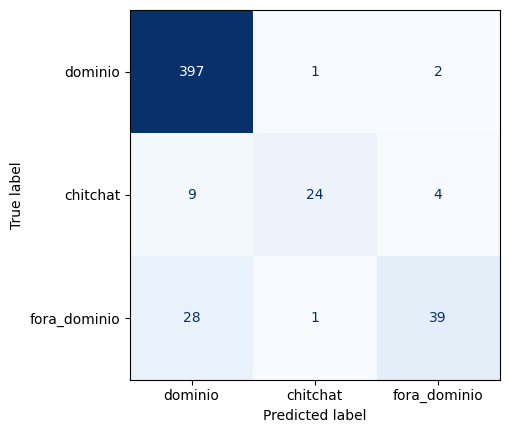

,texto,escopo,previsto,origem
1,Aoba…,chitchat,fora_dominio,coletado
3,"""Como eu faço tal coisa...""",chitchat,dominio,coletado
4,Começaria com a minha pergunta direto. Mas se tiver que escolher: oi,chitchat,dominio,coletado
5,Eae,chitchat,fora_dominio,coletado
9,Ei\nMe ajuda a resolver tal problema…,chitchat,dominio,coletado
23,como posso encontrar oportunidades de estágio via ufms?,fora_dominio,dominio,coletado
25,Reformula este email de modo formal,fora_dominio,dominio,coletado
26,Pode ajudar-me a organizar um plano de estudos semanal para preparar a entre...,fora_dominio,dominio,coletado
27,Quais são os próximos eventos culturais ou torneios desportivos programados ...,fora_dominio,dominio,coletado
29,Como meus dados são tratados na UFMS ?,fora_dominio,dominio,coletado


In [13]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 TODO: mesma metodologia, treinando **só** com as mensagens do domínio.

In [14]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF palavras,Regressão logística,0.947,0.023,0.948,1.0
1,TF-IDF caracteres,Regressão logística,0.943,0.026,0.943,1.0
2,TF-IDF caracteres,Rede neural (MLP),0.901,0.041,0.900,1.0
3,TF-IDF palavras,Rede neural (MLP),0.894,0.016,0.895,1.0
4,TF-IDF palavras,Árvore de decisão,0.859,0.021,0.860,1.0
5,TF-IDF caracteres,Árvore de decisão,0.829,0.026,0.830,1.0


In [15]:
# 🔨 TODO: ajuste de hiperparâmetros e escolha do modelo de tema
busca_tema = GridSearchCV(
    Pipeline([
        ("vetorizador", tfidf_caracteres()),
        ("classificador", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_tema.best_estimator_  # <--- É aqui que a variável é criada!

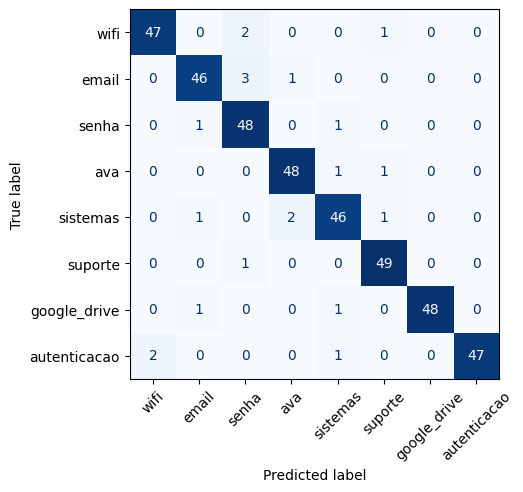

              precision    recall  f1-score   support

autenticacao       1.00      0.94      0.97        50
         ava       0.94      0.96      0.95        50
       email       0.94      0.92      0.93        50
google_drive       1.00      0.96      0.98        50
       senha       0.89      0.96      0.92        50
    sistemas       0.92      0.92      0.92        50
     suporte       0.94      0.98      0.96        50
        wifi       0.96      0.94      0.95        50

    accuracy                           0.95       400
   macro avg       0.95      0.95      0.95       400
weighted avg       0.95      0.95      0.95       400



In [16]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

In [17]:
# 🔨 TODO
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict

# 1. Obter probabilidades via validação cruzada (5 folds) no treino do domínio
probas_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv, method="predict_proba")
max_probas = probas_tema.max(axis=1)

# 2. Identificar acertos e erros
prevs_tema = clf_tema.classes_[probas_tema.argmax(axis=1)]
corretos = (prevs_tema == treino_dom["intencao"].values)

print("=== DISTRIBUIÇÃO DE CONFIANÇA DO MODELO DE TEMA ===")
print(f"Média de confiança nos ACERTOS: {max_probas[corretos].mean():.2%}")
print(f"Média de confiança nos ERROS:   {max_probas[~corretos].mean():.2%}")

# 3. Simulação de diferentes limiares
print("\n=== SIMULAÇÃO DE IMPACTO DO LIMIAR ===")
for limiar in [0.20, 0.25, 0.30, 0.35, 0.40]:
    aceitos = max_probas >= limiar
    acc_aceitos = corretos[aceitos].mean() if aceitos.sum() > 0 else 0
    erros_evitados = (~corretos & ~aceitos).sum()
    print(f"Limiar {limiar:.2f} -> Aceitos: {aceitos.sum():2d}/{len(treino_dom)} | Acurácia nas aceitas: {acc_aceitos:.1%} | Erros evitados: {erros_evitados}")

=== DISTRIBUIÇÃO DE CONFIANÇA DO MODELO DE TEMA ===
Média de confiança nos ACERTOS: 88.66%
Média de confiança nos ERROS:   55.47%

=== SIMULAÇÃO DE IMPACTO DO LIMIAR ===
Limiar 0.20 -> Aceitos: 400/400 | Acurácia nas aceitas: 94.8% | Erros evitados: 0
Limiar 0.25 -> Aceitos: 400/400 | Acurácia nas aceitas: 94.8% | Erros evitados: 0
Limiar 0.30 -> Aceitos: 396/400 | Acurácia nas aceitas: 95.2% | Erros evitados: 2
Limiar 0.35 -> Aceitos: 393/400 | Acurácia nas aceitas: 95.9% | Erros evitados: 5
Limiar 0.40 -> Aceitos: 388/400 | Acurácia nas aceitas: 96.1% | Erros evitados: 6


---
## 7. Salvar os modelos finais

In [18]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [19]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.grafo import Conversa
from chatbot.modelos import carregar_classificadores

config = carregar_config("grupo.yaml")
base = BaseConhecimento.carregar_ou_criar(config)
conversa = Conversa(
    config, *carregar_classificadores(config), usar_llm=True, base=base
)

perguntas = [
    "Como conecto meu notebook com Windows 11 ao Wi-Fi eduroam da UFMS?",
    "Qual vai ser a data da próxima manutenção da rede eduroam?",
    "Qual é a programação de cinema deste fim de semana?",
]

for pergunta in perguntas:
    estado = conversa.enviar(pergunta)
    print(pergunta)
    print(estado["rota"], estado["fonte_resposta"])
    print(estado["resposta"], "\n")

print("Fontes recuperadas para a primeira pergunta")
for trecho, _ in base.buscar(perguntas[0], intencao="wifi", k=3):
    print(trecho.fonte, trecho.pagina)

[base de conhecimento] 21 documento(s) -> 186 trechos (tfidf); índice salvo em /content/UniTi-ChatBot/.vectordb/indice.joblib
[aviso] LLM desligado: Chave do OpenRouter não encontrada. Crie um arquivo .env na raiz do repositório com a linha OPENROUTER_API_KEY=sk-or-... (veja .env.exemplo) ou, no Colab, cadastre o segredo OPENROUTER_API_KEY.
Como conecto meu notebook com Windows 11 ao Wi-Fi eduroam da UFMS?
wifi fixa
Posso ajudar com o acesso ao Wi-Fi institucional da UFMS. Consulte os tutoriais de configuração da rede Eduroam disponíveis na base de documentos. 

Qual vai ser a data da próxima manutenção da rede eduroam?
wifi fixa
Posso ajudar com o acesso ao Wi-Fi institucional da UFMS. Consulte os tutoriais de configuração da rede Eduroam disponíveis na base de documentos. 

Qual é a programação de cinema deste fim de semana?
fora_dominio fixa
Desculpe, não sei responder sobre isso. Posso ajudar com: Ajuda com acesso e configuração da rede Wi-Fi institucional Eduroam., Ajuda com acess

In [ ]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

In [ ]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "TODO: escreva mensagens do seu domínio", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [20]:
!python scripts/avaliar.py --quieto


Grupo: UniTi  |  Tema: UniTi - Chat Bot de Assistência com Tecnologias Acadêmicasr  |  Teste: /content/UniTi-ChatBot/dados/teste.csv (141 mensagens)

                              n  acurácia  F1 macro
nível                                              
escopo (1º estágio)         141     0.823     0.808
tema (2º estágio, oráculo)   71     0.887     0.789
ponta a ponta (grafo)       141     0.766     0.705

falso aceite           0.329
falsa recusa           0.014
esclarecimentos        0.000
latência média (ms)    7.781

Resultados salvos em /content/UniTi-ChatBot/resultados/avaliacao.json


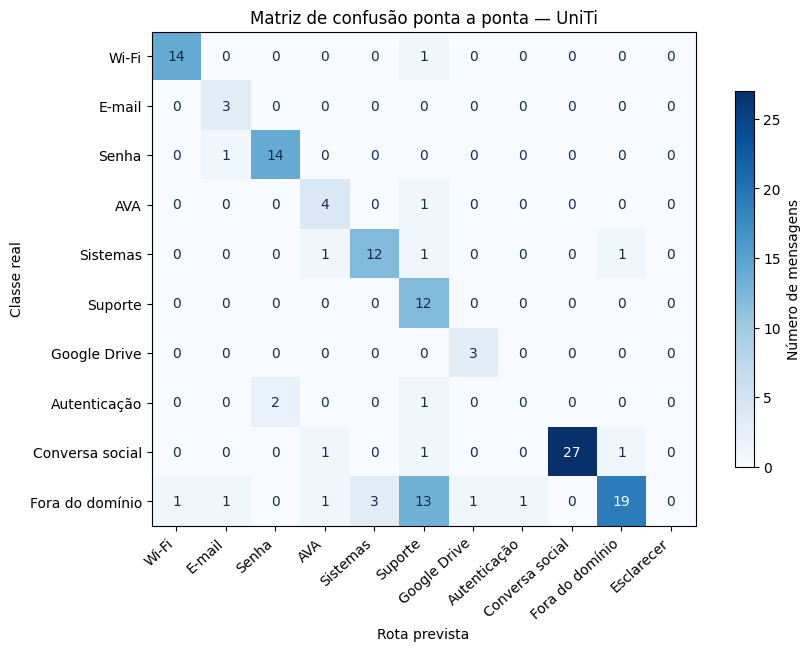

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

pasta = Path("/content/UniTi-ChatBot/resultados")
dados = json.loads((pasta / "avaliacao.json").read_text(encoding="utf-8"))["ponta_a_ponta"]
matriz = np.array(dados["matriz_confusao"])

nomes = {
    "wifi": "Wi-Fi", "email": "E-mail", "senha": "Senha", "ava": "AVA",
    "sistemas": "Sistemas", "suporte": "Suporte", "google_drive": "Google Drive",
    "autenticacao": "Autenticação", "chitchat": "Conversa social",
    "fora_dominio": "Fora do domínio", "esclarecer": "Esclarecer",
}

fig, ax = plt.subplots(figsize=(9, 6.4), layout="constrained")
mapa = ax.imshow(matriz, cmap="Blues", vmin=0)
ax.set_xticks(range(matriz.shape[1]), [nomes[r] for r in dados["rotulos_previstos"]],
              rotation=42, ha="right")
ax.set_yticks(range(matriz.shape[0]), [nomes[r] for r in dados["rotulos"]])
ax.set(xlabel="Rota prevista", ylabel="Classe real",
       title="Matriz de confusão ponta a ponta — UniTi")
for (i, j), valor in np.ndenumerate(matriz):
    cor = "white" if valor >= 0.65 * matriz.max() else "#172b4d"
    ax.text(j, i, str(valor), ha="center", va="center", color=cor)
fig.colorbar(mapa, ax=ax, shrink=0.76, label="Número de mensagens")

saida = pasta / "matriz_confusao_uniti.pdf"
fig.savefig(saida, bbox_inches="tight")
plt.show()
files.download(str(saida))

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [ ]:
!{sys.executable} scripts/verificar_entrega.py